In [111]:
import pandas as pd
import geopandas as gpd
import h3pandas
from shapely.geometry import Polygon
import tskit
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
import PIL
from IPython.display import display, Image
import io

import rasterio
from rasterio.vrt import WarpedVRT
from rasterio import transform
import rasterstats
import matplotlib.pyplot as plt
import rasterio.mask
from rasterio.plot import show

import random
import math
import glob


# Make a list of latitudes and longitudes of the four points
# the fifth point is the first point to make last edge of polygon go back to start

lat_point_list = [33.619523, 33.968163, 72.575236, 72.533312, 33.619523]
lon_point_list = [-12.321952, 46.271179, 40.677562, -11.343070, -12.321952]

polygon_geometry = Polygon(zip(lon_point_list, lat_point_list))
rectangle_polygon_geometry = Polygon([[polygon_geometry.bounds[0], polygon_geometry.bounds[1]],
                                      [polygon_geometry.bounds[2], polygon_geometry.bounds[1]],
                                      [polygon_geometry.bounds[2], polygon_geometry.bounds[3]],
                                      [polygon_geometry.bounds[0], polygon_geometry.bounds[3]],
                                      [polygon_geometry.bounds[0], polygon_geometry.bounds[1]]])
crs = "epsg:4326"
shp = gpd.GeoDataFrame(index=[0], crs=crs, geometry=[rectangle_polygon_geometry])

resolution = 2
hex_euro = shp.h3.polyfill_resample(resolution).sort_index().reset_index()
hex_euro["deme"] = hex_euro.index

xs = hex_euro.centroid.x
ys = hex_euro.centroid.y

hex_euro["from_top"] = 0.00000000001 * (10000000 ** (1-((ys - min(ys)) / (max(ys) - min(ys)))))

mean_x = np.mean(xs)
mean_y = np.mean(ys)
distances = (xs-mean_x)**2 + (ys-mean_y)**2
hex_euro["from_center"] = 0.00000000001 * (1000000 ** (1 - (distances - min(distances)) / (max(distances) - min(distances))))


mask = []
for i in range(len(xs)):
    if (ys[i] > xs[i]*0.25 + 60):
        mask.append(0)
    else:
        mask.append(1)
hex_euro["mask"] = mask

for t in range(0, 121000, 1000):
    if (t < 21000 or t % 2000 == 0):
        with rasterio.open(f"../1_generating_suitability_maps/datasets/Beyer_High-resolutionTerrestrialClimate_2020/data/suitability_reconstructions/{t}.grd") as src_dst:
            mean_suitability = []
            for stat in rasterstats.zonal_stats(
                hex_euro,
                np.nan_to_num(src_dst.read(1), nan=0.0),
                affine=src_dst.transform,
                stats="mean",
                nodata=-999999
            ):
                mean_suitability.append(stat["mean"])
            if t > 10000:
                hex_euro.loc[:,f"mean_suitability_{t}"] = mean_suitability * hex_euro["mask"] + hex_euro["from_center"]
            else:
                hex_euro.loc[:,f"mean_suitability_{t}"] = mean_suitability + hex_euro["from_center"]

/var/folders/q7/rz2nckpx02s10jlx05wbk6c00000gn/T/ipykernel_25322/122409150.py:44: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  xs = hex_euro.centroid.x
/var/folders/q7/rz2nckpx02s10jlx05wbk6c00000gn/T/ipykernel_25322/122409150.py:45: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  ys = hex_euro.centroid.y


In [112]:
import sys
sys.path.append("/Users/jameskitchens/Documents/GitHub/terracotta")
import terracotta as tct
import pandas as pd
import tskit

demes = pd.read_csv("../2_creating_input_files/dataset/demes.tsv", sep="\t")
connections = pd.read_csv("../2_creating_input_files/dataset/connections.tsv", sep="\t")

#clade = [1, 40, 37, 39]
samples = pd.read_csv("../2_creating_input_files/dataset/samples.tsv", sep="\t")
#samples = samples.loc[samples["id"].isin(clade), :]
#samples["old_id"] = samples["id"]
#samples["id"] = [0, 2, 3, 1]
#samples = samples.reset_index(drop=True)

world_map = tct.WorldMap(demes, connections, samples)

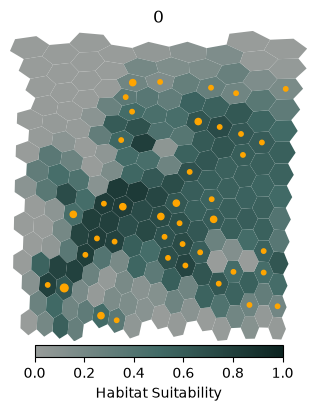

In [113]:
colors = ["#989C9A", "#416A66", "#0C2320"]
cmap = LinearSegmentedColormap.from_list("mycmap", colors)

base = hex_euro.plot(
    column=f"mean_suitability_0",
    legend=True,
    legend_kwds={"label": "Habitat Suitability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap=cmap,
    vmin=0,
    vmax=1
)

#subsamples = [0, 16, 32, 27, 33, 3, 24, 45, 22, 1, 40, 5, 37, 39, 6, 26, 49]

important = samples.loc[:, "deme"]

xs = []
ys = []
ss = []
for i,row in hex_euro.iterrows():
    count = list(important).count(row["deme"])
    if count > 0:
        center = row["geometry"].centroid
        xs.append(center.x)
        ys.append(center.y)
        ss.append(count*10)

plt.scatter(xs, ys, s=ss, color="orange", zorder=20, label="Samples")

plt.title(0)
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

In [114]:
ts = tskit.load("../2_creating_input_files/dataset/trees/0.trees")
#tree_simplified = ts.simplify(samples=clade, keep_input_roots=True)
tree_simplified = ts.simplify(keep_input_roots=True)
tree_simplified = tree_simplified.first()

In [115]:
times = range(0,21000,1000)
locations = tct.track_lineage_over_time(
    sample=3,
    times=times,
    tree=tree_simplified,
    world_map=world_map,
    parameters=[0.00111981],
    method="new",
    coal=True
)

[    80     -1  -1001  -2001  -3001  -4001  -5001  -6001  -7001  -8001
  -9001 -10001 -11001 -12001 -13001 -14001 -15001 -16001 -17001 -17565
 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565
 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565
 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565
 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565
 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565 -17565
 -17565]
[    1  1001  2001  3001  4001  5001  6001  7001  8001  9001 10001 11001
 12001 13001 14001 15001 16001 17001 17565 17565 17565 17565 17565 17565
 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565
 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565
 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565
 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565 17565]


In [116]:
tree = ts.first()

lineage = []
time = []
deme = []

sample = 3
a = sample
previous_t = 0
while a != -1:
    t = ts.node(a).time
    pop = int(ts.population(ts.node(a).population).metadata["name"].split("_")[-1])
    lineage.append(sample)
    time.append(t)
    deme.append(pop)
    a = tree.parent(a)
    previous_t = t

true_locations = pd.DataFrame({"lineage":lineage, "time":time, "deme":deme})

KeyError: 0

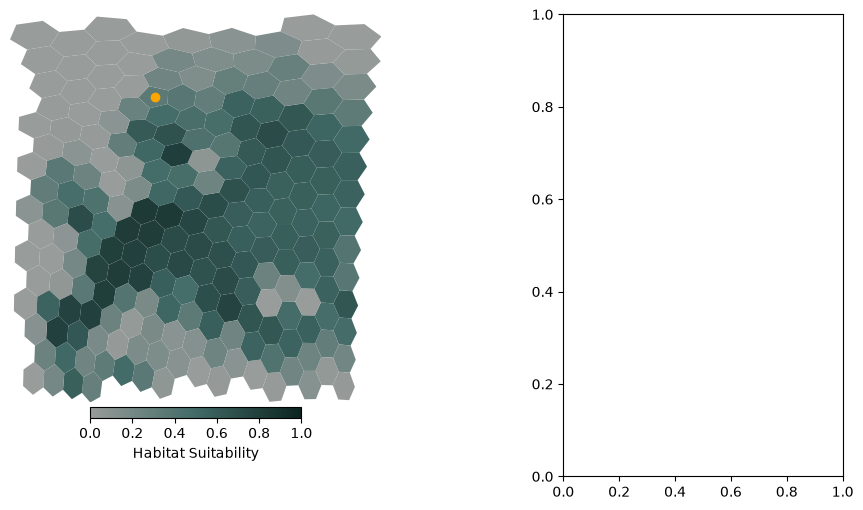

In [117]:
images = []
for i in range(len(locations)):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    hex_euro.plot(
        ax=ax1,
        column=f"mean_suitability_{times[i]}",
        legend=True,
        legend_kwds={"label": "Habitat Suitability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap=cmap,
        vmin=0,
        vmax=1
    )
    ax1.set_xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    ax1.set_ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    ax1.axis("off")

    filtered = true_locations.loc[(true_locations["time"]<=times[i])]
    filled_deme = list(filtered.loc[filtered["time"]==max(filtered["time"])]["deme"])[0]
    d = hex_euro.loc[hex_euro["deme"]==filled_deme].iloc[0]
    center = d["geometry"].centroid
    ax1.scatter(center.x, center.y, color="orange", zorder=20, label="Samples")
        
    
    hex_euro.plot(
        ax=ax2,
        column=locations[i],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )
    ax2.set_xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    ax2.set_ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    ax2.axis("off")
    
    fig.suptitle(f"{times[i]} Years Ago")
    plt.savefig(f"figures/{i}.png")
    plt.close()
    images.append(PIL.Image.open(f"figures/{i}.png"))

images[0].save("locations.gif", save_all=True, append_images=images[1:], duration=250, loop=0)
display(Image("locations.gif"))

In [74]:
times = range(0,21000,1000)
locations_new_coalpower1, messages_new_coalpower1 = track_lineage_over_time(
    sample=1,
    times=times,
    tree=tree_simplified,
    world_map=world_map,
    parameters=[0.00111981],
    method="new",
    coal=True
)
locations_new_coalpower0, messages_new_coalpower0 = track_lineage_over_time(
    sample=1,
    times=times,
    tree=tree_simplified,
    world_map=world_map,
    parameters=[0.00111981],
    method="new",
    coal=False
)
locations_old_coalpower1, messages_old_coalpower1 = track_lineage_over_time(
    sample=1,
    times=times,
    tree=tree_simplified,
    world_map=world_map,
    parameters=[0.00111981],
    method="old",
    coal=True
)
locations_old_coalpower0, messages_old_coalpower0 = track_lineage_over_time(
    sample=1,
    times=times,
    tree=tree_simplified,
    world_map=world_map,
    parameters=[0.00111981],
    method="old",
    coal=False
)

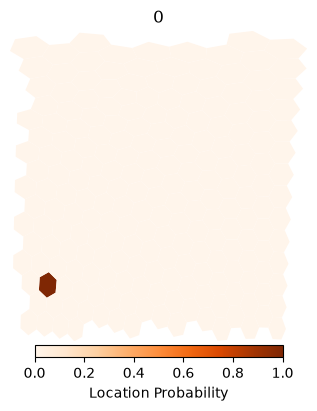

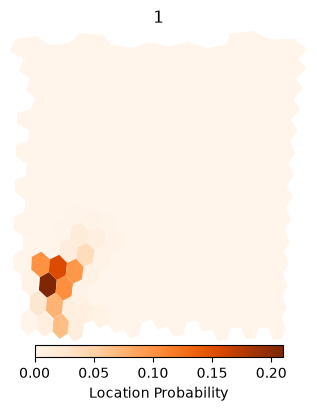

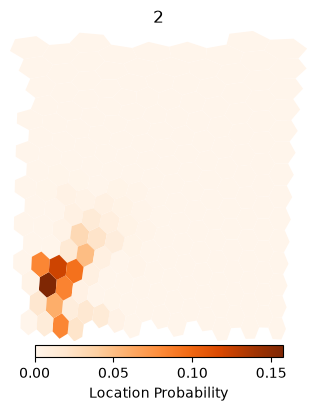

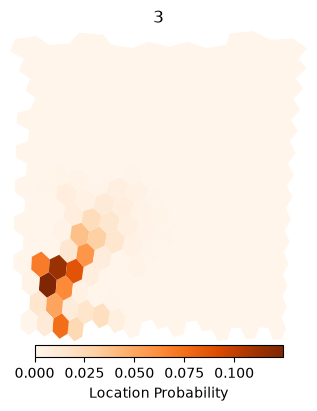

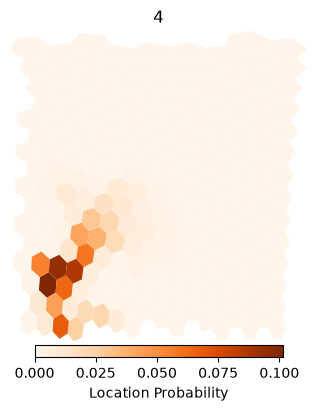

...

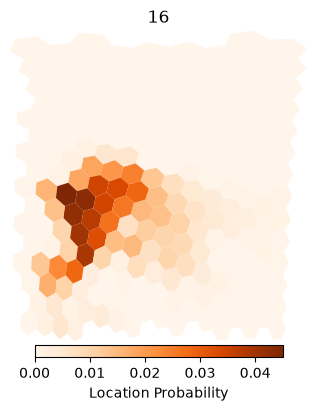

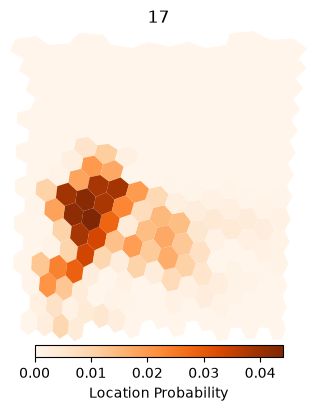

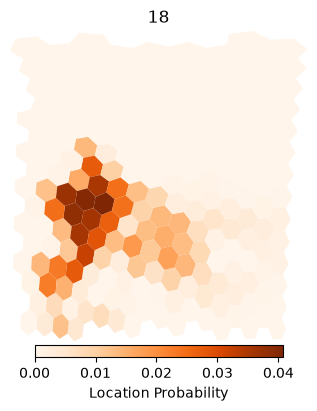

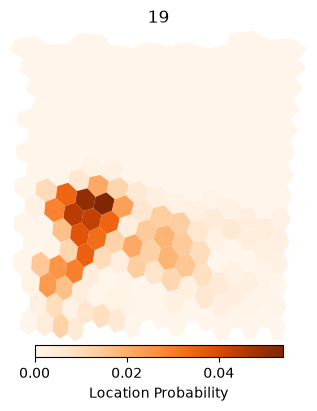

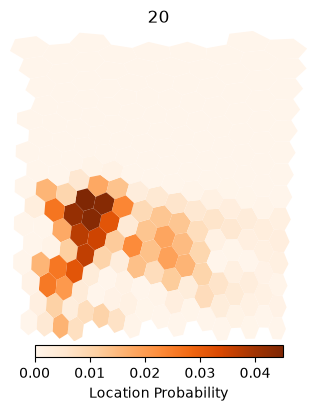

In [62]:
for i in range(len(locations_new_coalpower0)):
    base = hex_euro.plot(
        column=locations_new_coalpower0[i],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )

    plt.title(i)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

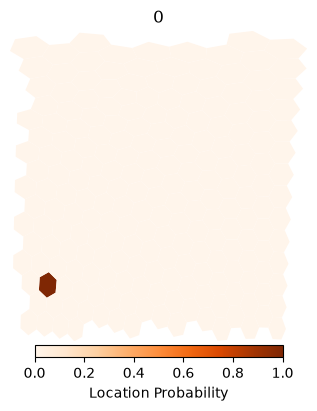

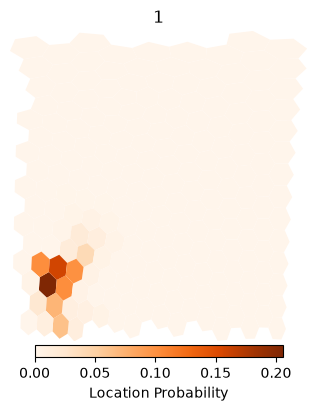

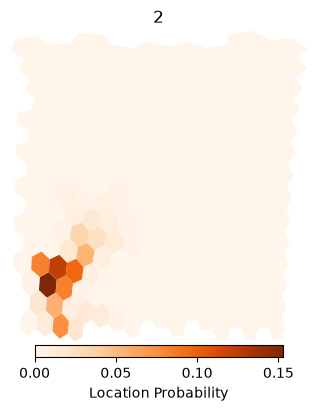

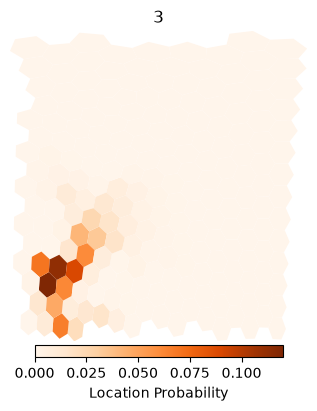

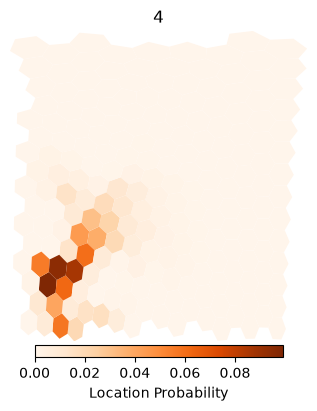

...

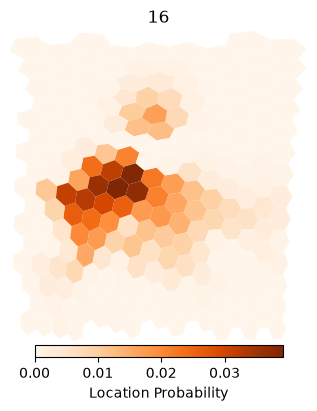

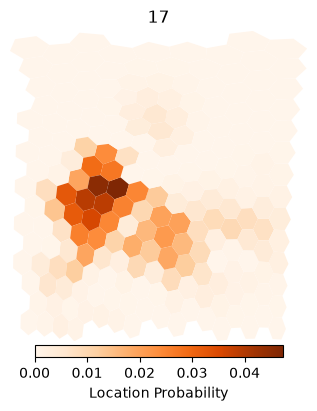

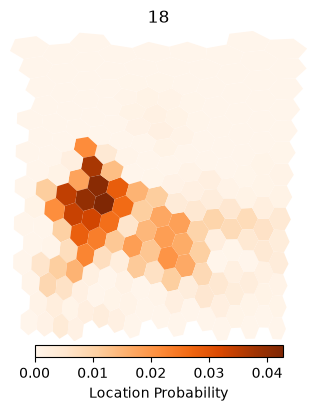

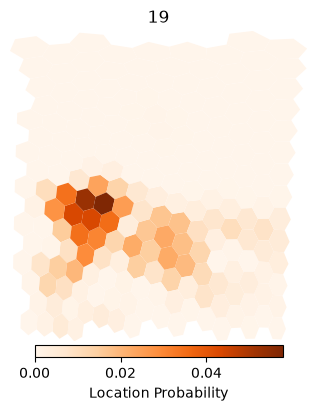

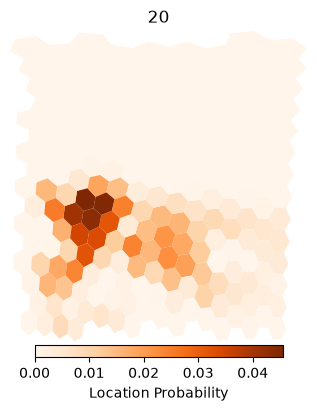

In [63]:
for i in range(len(locations_old_coalpower1)):
    base = hex_euro.plot(
        column=locations_old_coalpower1[i],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )

    plt.title(i)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

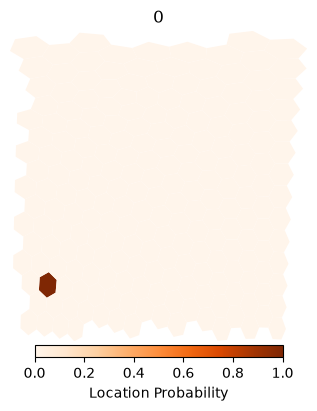

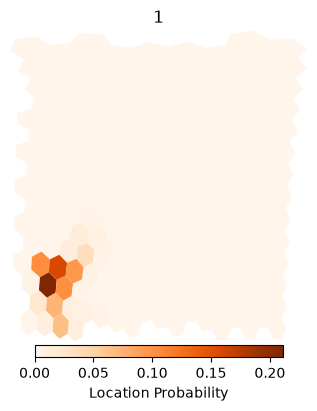

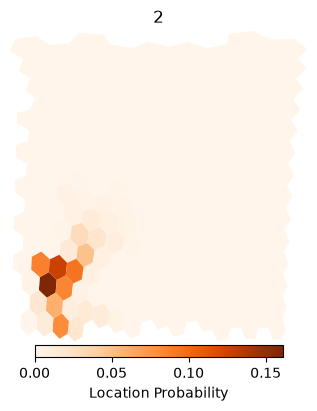

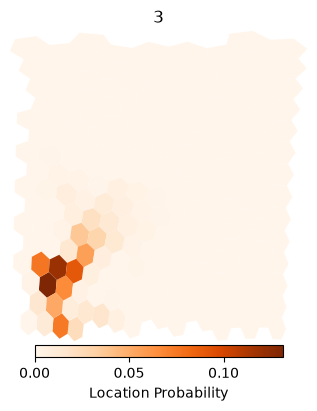

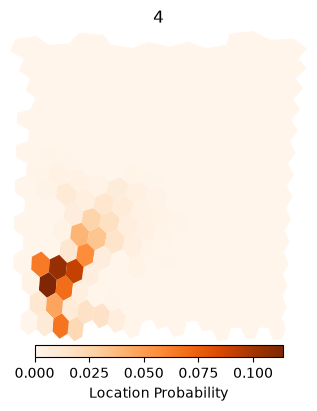

...

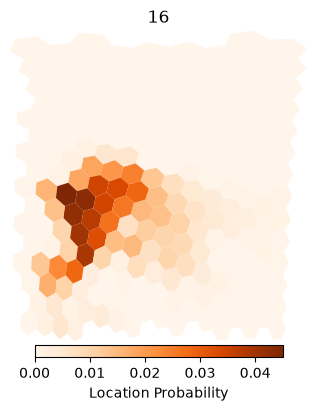

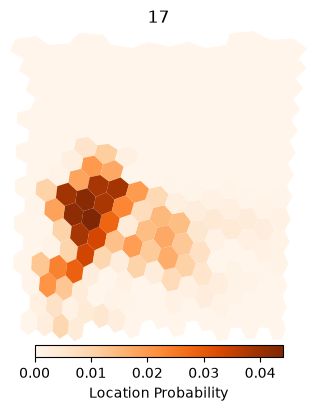

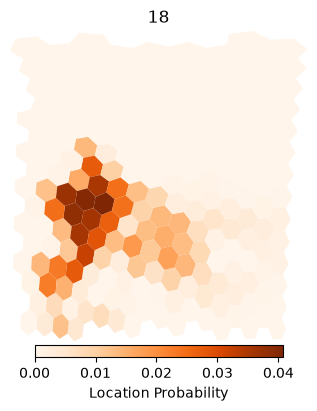

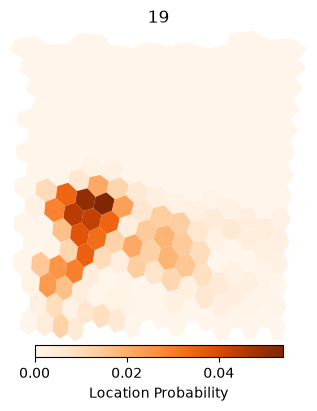

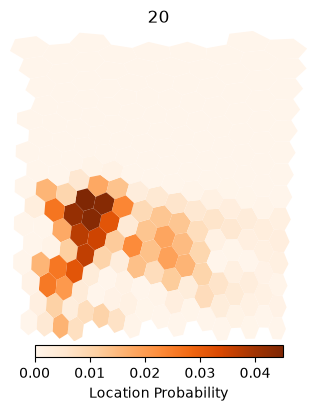

In [64]:
for i in range(len(locations_old_coalpower0)):
    base = hex_euro.plot(
        column=locations_old_coalpower0[i],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )

    plt.title(i)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

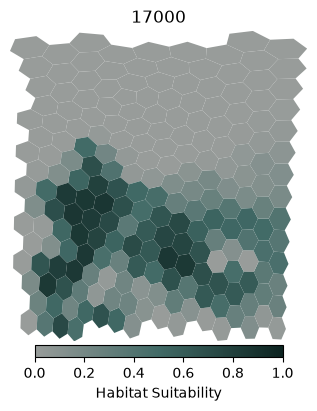

In [18]:
base = hex_euro.plot(
    column="mean_suitability_17000",
    legend=True,
    legend_kwds={"label": "Habitat Suitability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap=cmap,
    vmin=0,
    vmax=1
)

plt.title(17000)
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

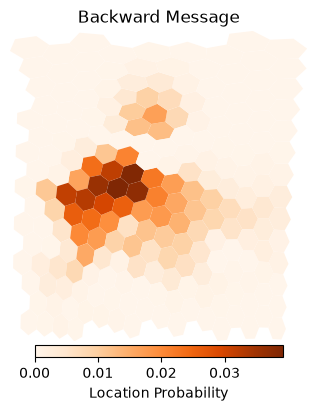

In [7]:
base = hex_euro.plot(
    column=locations_new_coalpower1,
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.title("Backward Message")
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

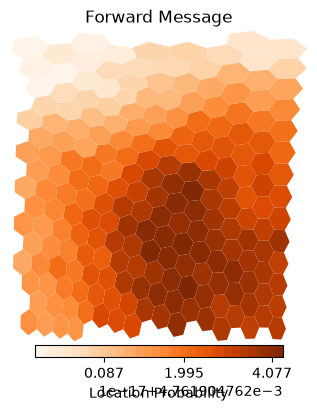

In [11]:
base = hex_euro.plot(
    column=messages_new_coalpower1,
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.title("Forward Message")
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

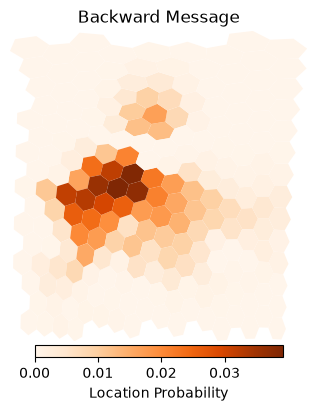

In [13]:
base = hex_euro.plot(
    column=locations_old_coalpower1,
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.title("Backward Message")
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

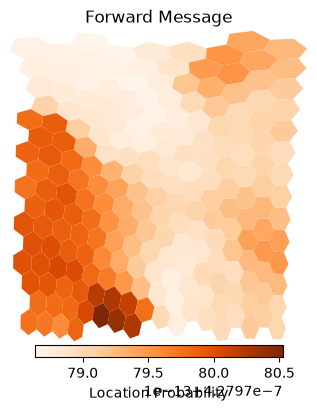

In [12]:
base = hex_euro.plot(
    column=messages_old_coalpower1,
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.title("Forward Message")
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

In [14]:
messages_old_coalpower1

array([4.27977939e-07, 4.27977895e-07, 4.27977953e-07, 4.27977927e-07,
       4.27977870e-07, 4.27977869e-07, 4.27977873e-07, 4.27977875e-07,
       4.27977875e-07, 4.27977868e-07, 4.27977875e-07, 4.27977863e-07,
       4.27977881e-07, 4.27977879e-07, 4.27977874e-07, 4.27977882e-07,
       4.27977878e-07, 4.27977870e-07, 4.27977867e-07, 4.27977873e-07,
       4.27977919e-07, 4.27977948e-07, 4.27977899e-07, 4.27977934e-07,
       4.27977876e-07, 4.27977889e-07, 4.27977876e-07, 4.27977878e-07,
       4.27977869e-07, 4.27977887e-07, 4.27977878e-07, 4.27977880e-07,
       4.27977874e-07, 4.27977906e-07, 4.27977866e-07, 4.27977880e-07,
       4.27977870e-07, 4.27977871e-07, 4.27977863e-07, 4.27977870e-07,
       4.27977888e-07, 4.27977882e-07, 4.27977891e-07, 4.27977876e-07,
       4.27977911e-07, 4.27977884e-07, 4.27977935e-07, 4.27977915e-07,
       4.27977897e-07, 4.27977908e-07, 4.27977907e-07, 4.27977905e-07,
       4.27977900e-07, 4.27977910e-07, 4.27977904e-07, 4.27977901e-07,
      

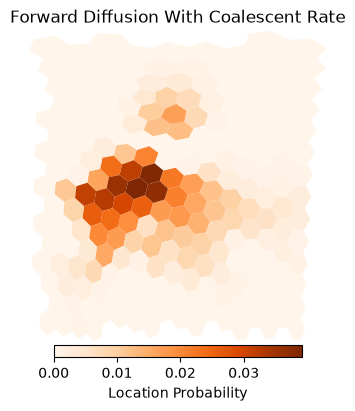

In [11]:
base = hex_euro.plot(
    column=locations_new_coalpower1[16],
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.title("Forward Diffusion With Coalescent Rate")
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

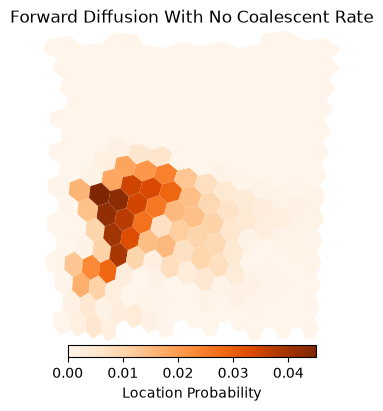

In [19]:
base = hex_euro.plot(
    column=locations_new_coalpower0[16],
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.title("Forward Diffusion With No Coalescent Rate")
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

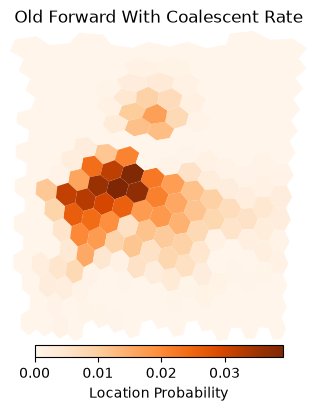

In [21]:
base = hex_euro.plot(
    column=locations_old_coalpower1[16],
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.title("Old Forward With Coalescent Rate")
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

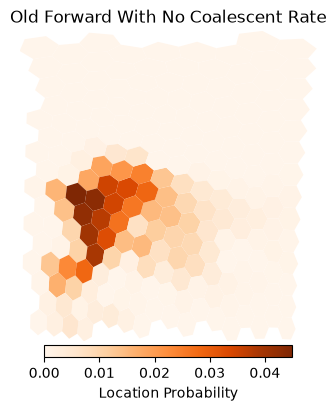

In [22]:
base = hex_euro.plot(
    column=locations_old_coalpower0[16],
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.title("Old Forward With No Coalescent Rate")
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

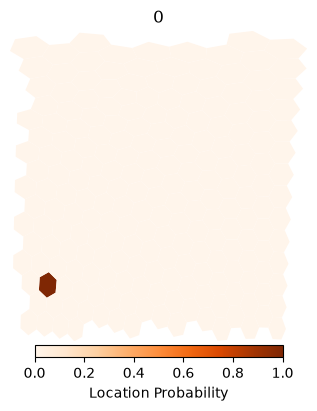

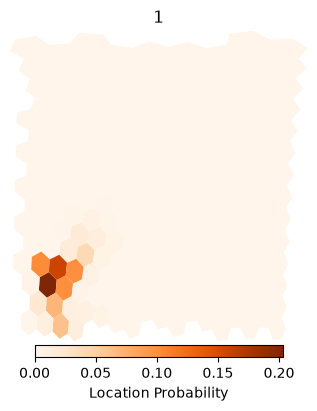

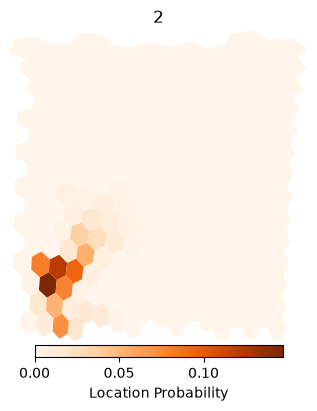

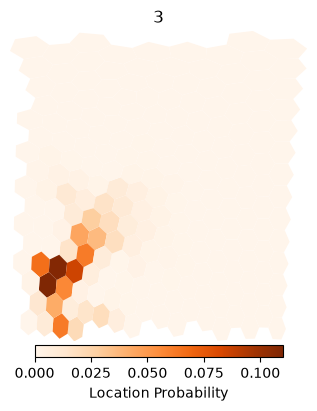

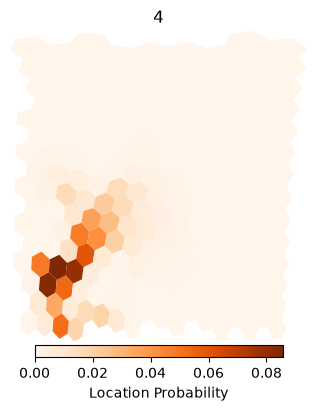

...

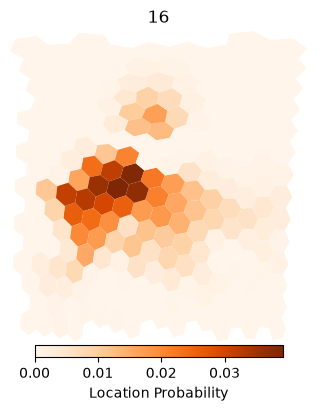

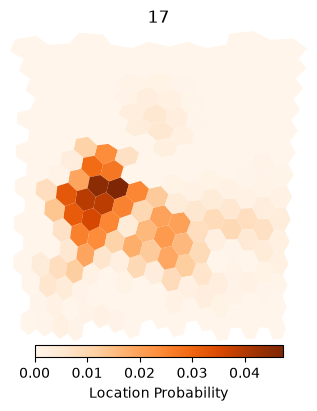

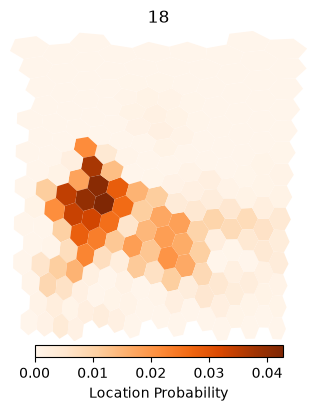

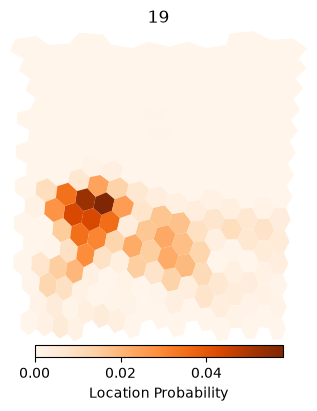

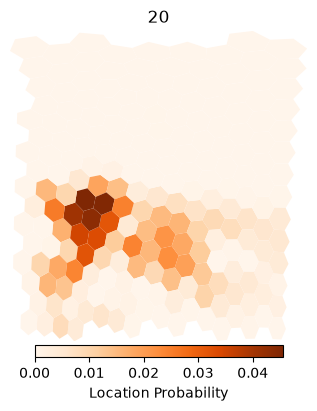

In [60]:
for i in range(len(locations_new_coalpower1)):
    base = hex_euro.plot(
        column=locations_new_coalpower1[i],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )

    plt.title(i)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

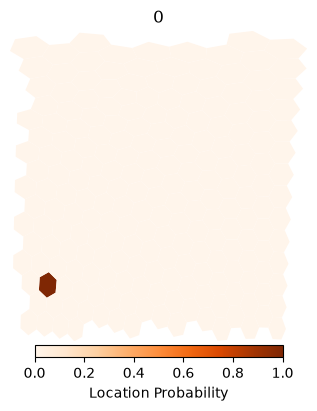

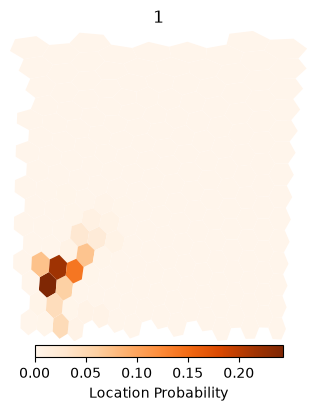

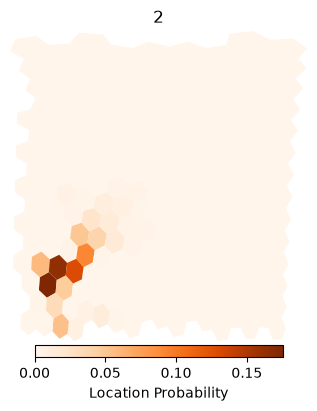

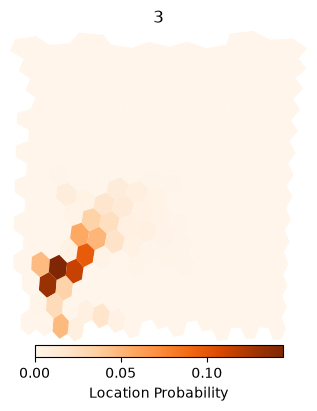

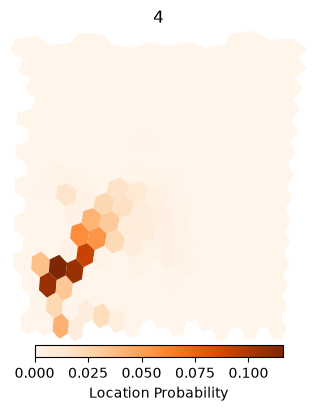

...

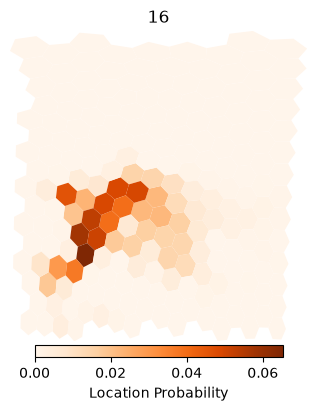

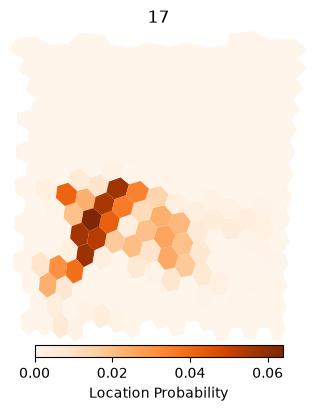

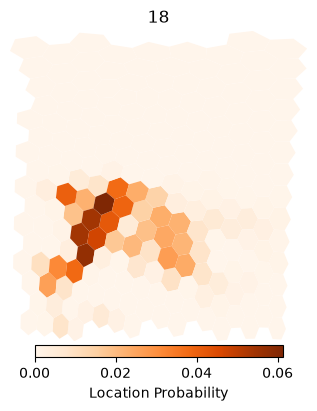

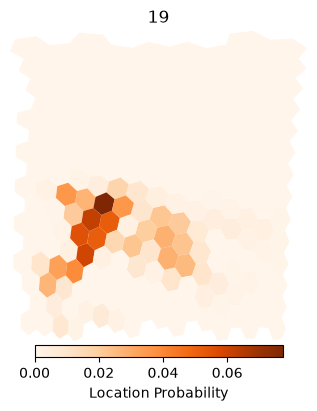

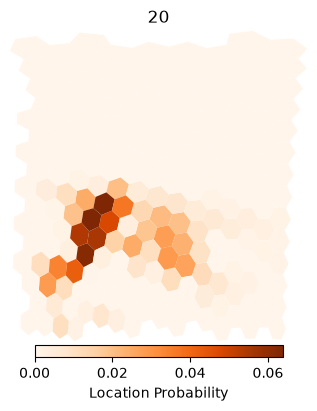

In [8]:
for i in range(len(locations_old)):
    base = hex_euro.plot(
        column=locations_old[i],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )

    plt.title(i)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

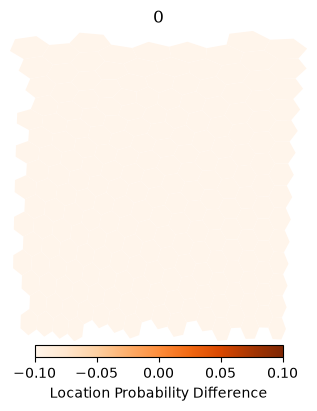

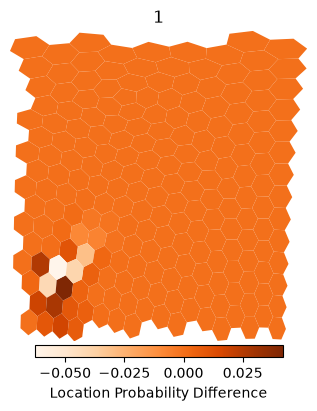

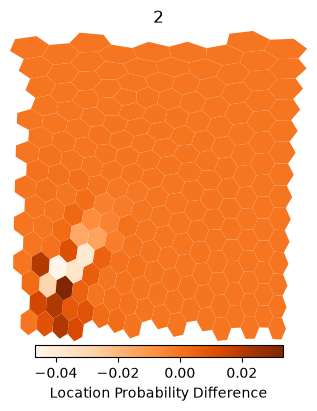

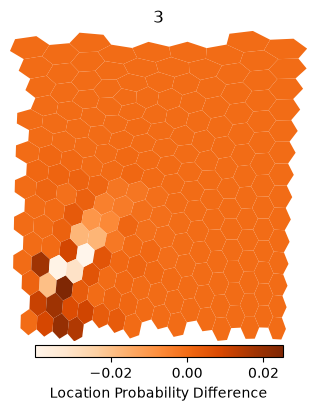

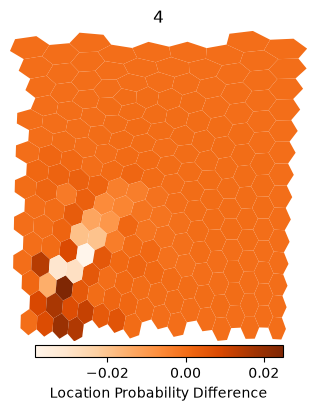

...

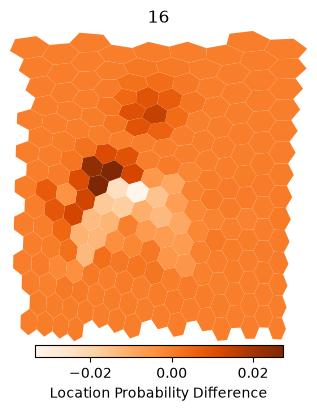

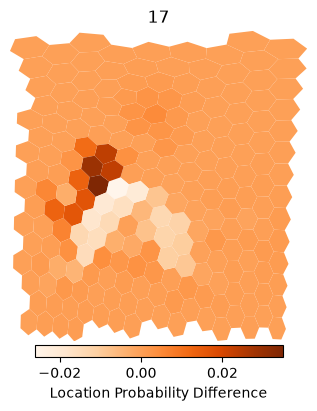

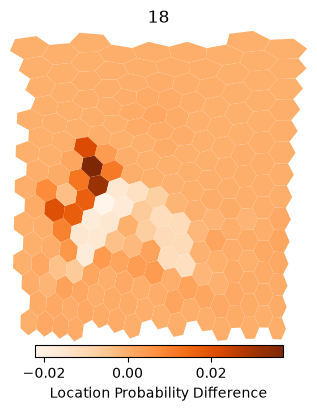

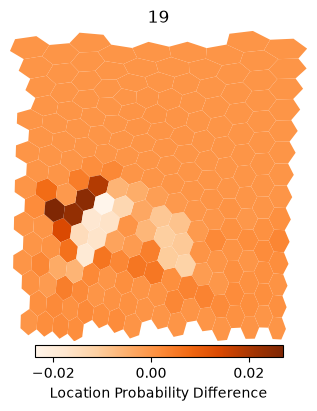

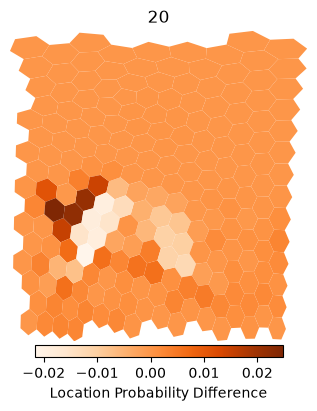

In [9]:
for i in range(len(locations_new)):
    base = hex_euro.plot(
        column=locations_new[i]-locations_old[i],
        legend=True,
        legend_kwds={"label": "Location Probability Difference", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )

    plt.title(i)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

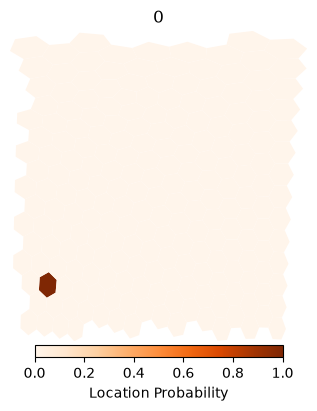

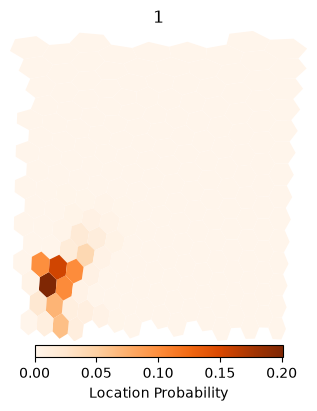

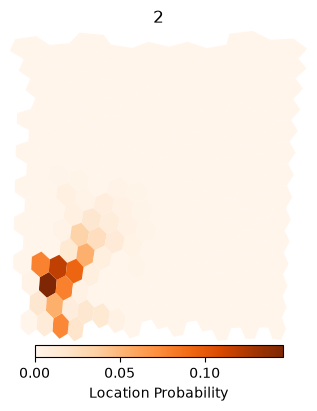

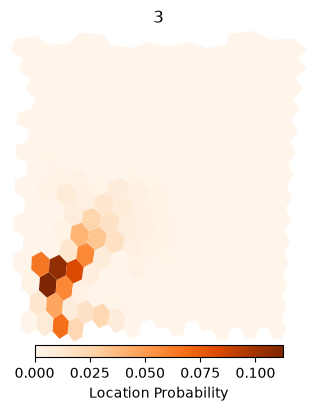

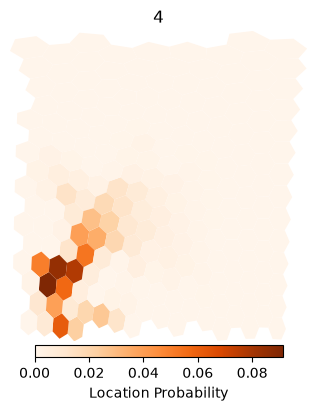

...

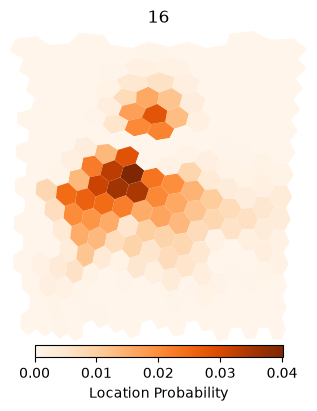

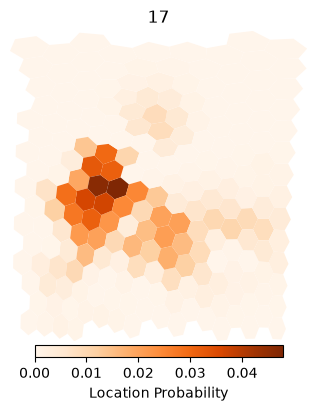

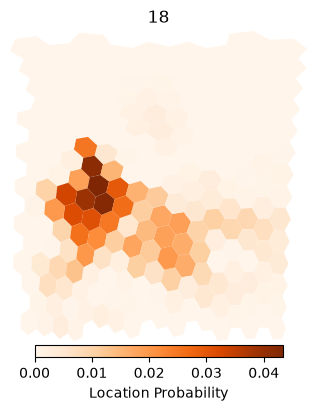

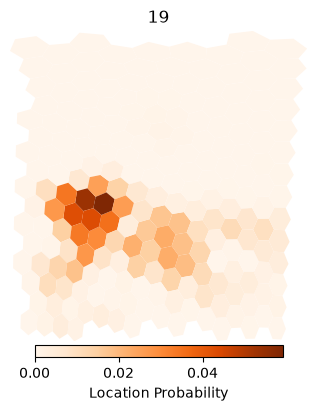

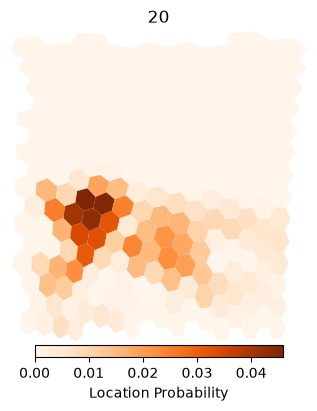

In [11]:
for t in range(len(times)):
    base = hex_euro.plot(
        column=locations_new[t],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )

    plt.title(t)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

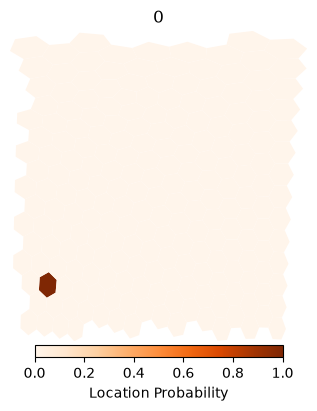

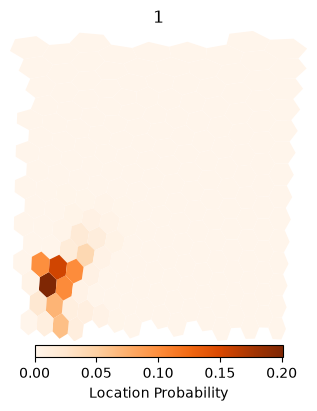

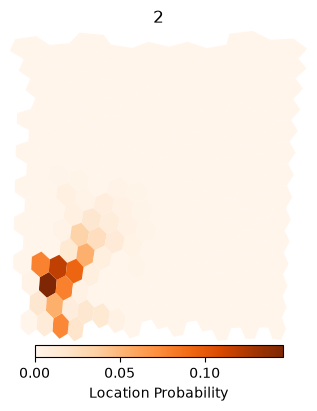

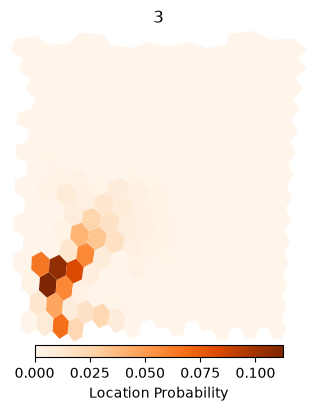

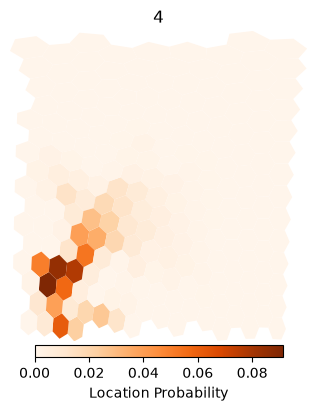

...

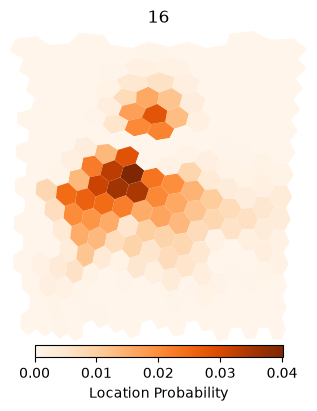

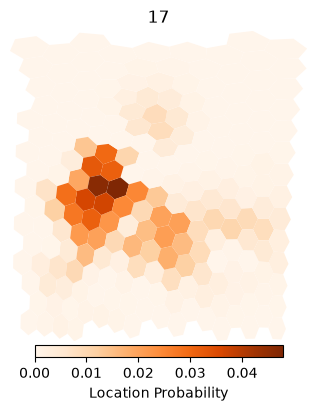

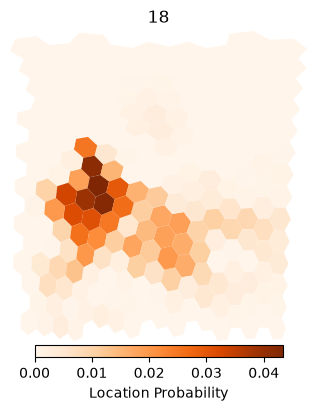

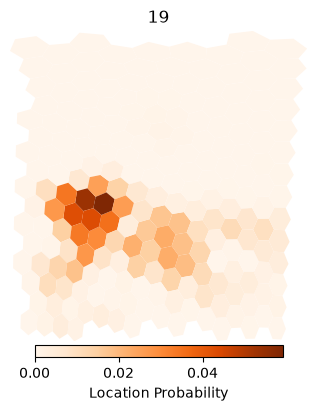

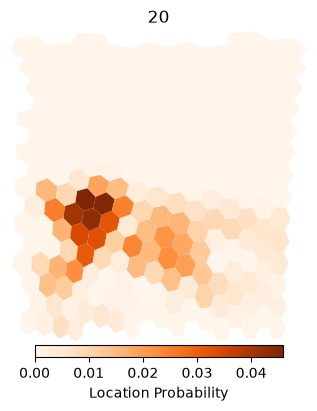

In [12]:
for t in range(len(times)):
    base = hex_euro.plot(
        column=locations_old[t],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )

    plt.title(t)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

In [7]:
ts = tskit.load("../2_creating_input_files/dataset/trees/0.trees")
tree = ts.first()

lineage = []
time = []
deme = []

for sample in ts.samples():
    a = sample
    while a != -1:
        t = ts.node(a).time
        pop = int(ts.population(ts.node(a).population).metadata["name"].split("_")[-1])
        lineage.append(sample)
        time.append(t)
        deme.append(pop)
        a = tree.parent(a)
    
true_locations = pd.DataFrame({"lineage":lineage, "time":time, "deme":deme})

0
1
2
3
4


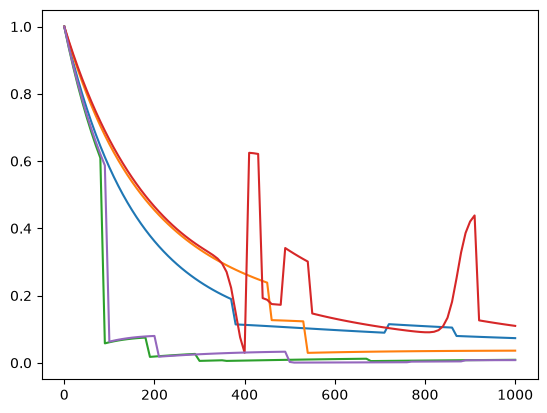

In [8]:
times = range(0,1010,10)
tree_simplified = ts.simplify(keep_input_roots=True).first()

counter = 0
for sample in ts.samples():
    if counter >= 5:
        break
    
    estimated_locations = tct.track_lineage_over_time(
        sample=sample,
        times=times,
        tree=tree_simplified,
        world_map=world_map,
        parameters=[0.00111981]
    )
    
    probs = []
    lineage_locations = true_locations.loc[true_locations["lineage"]==sample]
    for t,time in enumerate(times):
        filtered = lineage_locations.loc[(lineage_locations["time"]<=time)]
        filled_deme = list(filtered.loc[filtered["time"]==max(filtered["time"])]["deme"])[0]
        probs.append(estimated_locations[t][filled_deme])   
    plt.plot(times, probs)
    print(sample)
    counter += 1
plt.show()

In [27]:
suit_times = np.array([t for t in range(0, 121000, 1000) if (t < 21000 or t % 2000 == 0)])
tree = ts.first()

lineage = []
time = []
deme = []

sample = 0
a = sample
previous_t = 0
while a != -1:
    t = ts.node(a).time
    pop = int(ts.population(ts.node(a).population).metadata["name"].split("_")[-1])
    for st in suit_times[np.where((suit_times > previous_t) & (suit_times < t))[0]]:
        lineage.append(sample)
        time.append(st)
        deme.append(pop)
    lineage.append(sample)
    time.append(t)
    deme.append(pop)
    a = tree.parent(a)
    previous_t = t

locations = pd.DataFrame({"lineage":lineage, "time":time, "deme":deme})

In [28]:
locations

,lineage,time,deme
0,0,0.000000,128
1,0,375.186462,127
2,0,716.185981,123
3,0,864.668590,127
4,0,1000.000000,129
...,...,...,...
738,0,120604.400108,116
739,0,120818.206206,121
740,0,120822.347917,105
741,0,120990.939656,102


In [11]:
lineage = []
time = []
deme = []

tree = ts.first()
for sample in ts.samples():
    a = sample
    previous_t = 0
    while a != -1:
        t = ts.node(a).time
        pop = int(ts.population(ts.node(a).population).metadata["name"].split("_")[-1])
        for st in suit_times[np.where((suit_times > previous_t) & (suit_times < t))[0]]:
            lineage.append(sample)
            time.append(st)
            deme.append(pop)
        lineage.append(sample)
        time.append(t)
        deme.append(pop)
        a = tree.parent(a)
        previous_t = t

NameError: name 'suit_times' is not defined

In [10]:
base = hex_euro.plot(
    column=messages[7],
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

NameError: name 'messages' is not defined

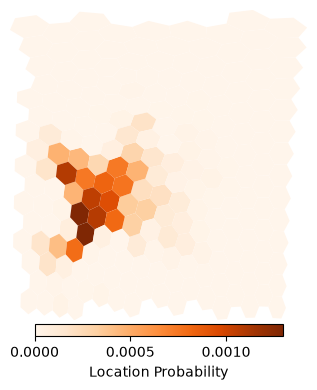

In [10]:
base = hex_euro.plot(
    column=np.multiply(messages[2], messages[3]),
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

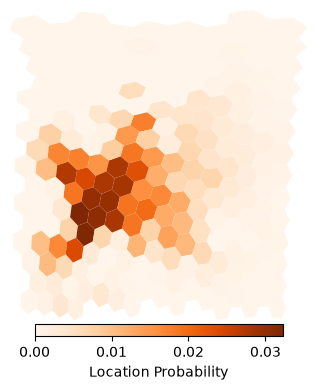

In [17]:
base = hex_euro.plot(
    column=messages[3],
    legend=True,
    legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap="Oranges"
)

plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

0
4
6


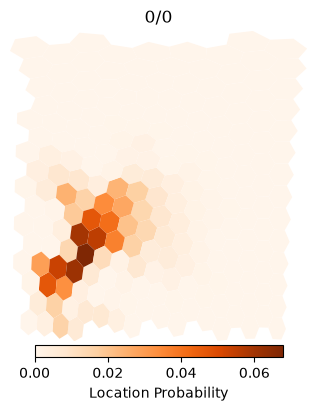

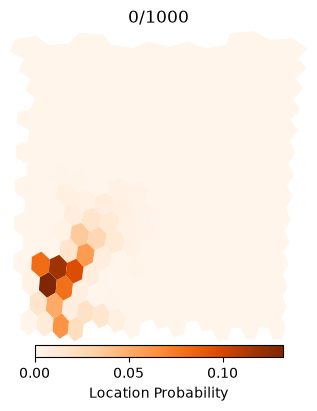

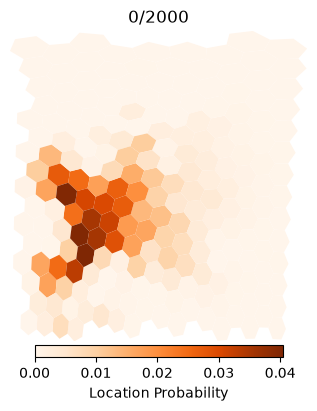

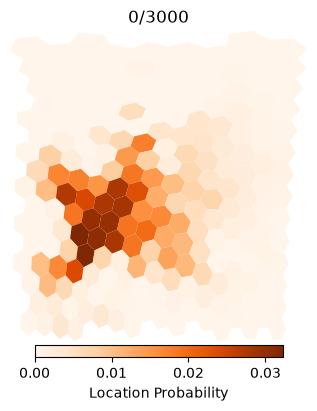

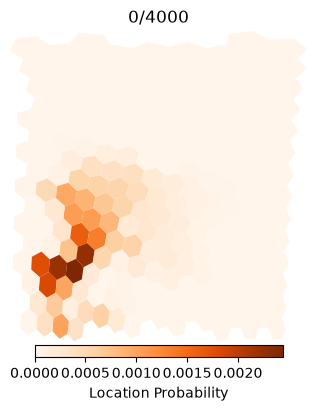

...

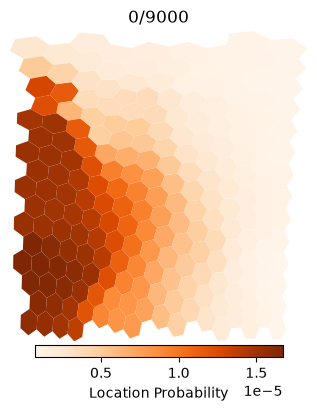

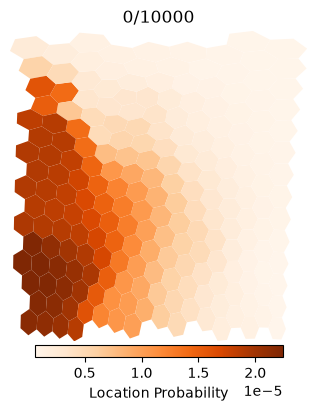

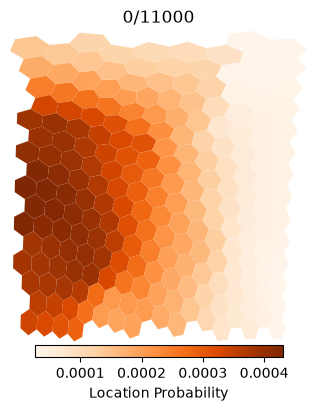

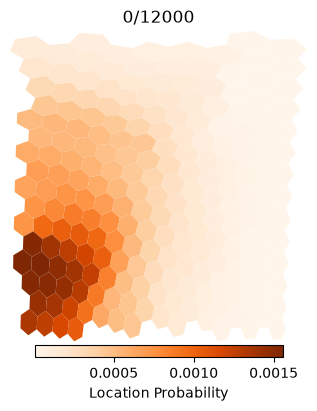

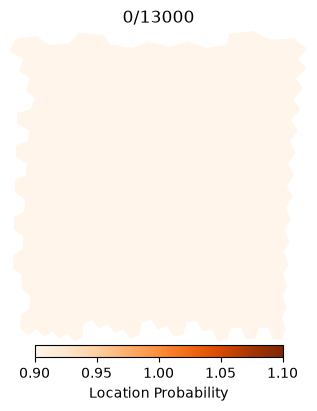

IndexError: index 14 is out of bounds for axis 0 with size 14

In [12]:
times = range(0,16000,1000)

for sample in range(4):

    locations = tct.track_lineage_over_time(
        sample=sample,
        times=times,
        tree=tree,
        world_map=world_map,
        parameters=[0.00037889]
    )
    
    for t,time in enumerate(times):
        hex_euro[f"locations_{time}"] = locations[t]
        
        base = hex_euro.plot(
            column=locations[t],
            legend=True,
            legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
            cmap="Oranges"
        )
        
        plt.title(f"{sample}/{time}")
        plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
        plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
        plt.axis("off")
        plt.show()

In [ ]:
ts = tskit.load("../2_creating_input_files/dataset/trees/0.trees")
tree = ts.simplify().first()

times = range(0,25000,1000)

locations = tct.track_lineage_over_time(
    sample=1,
    times=times,
    tree=tree,
    world_map=world_map,
    parameters=[0.00037889]
)

for t,time in enumerate(times):
    hex_euro[f"locations_{time}"] = locations[t]
    
    base = hex_euro.plot(
        column=locations[t],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )
    
    plt.title(time)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

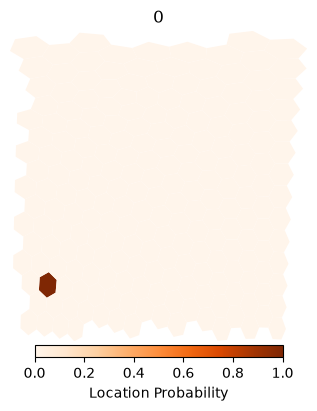

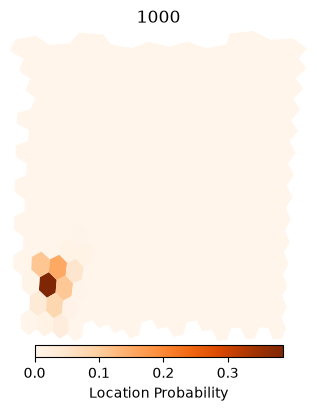

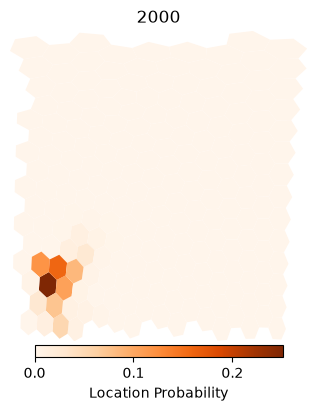

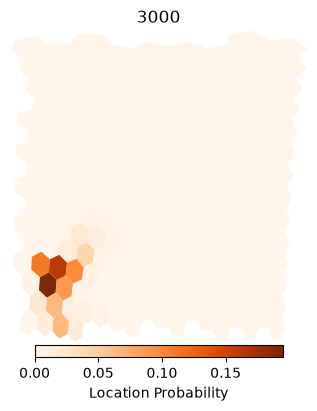

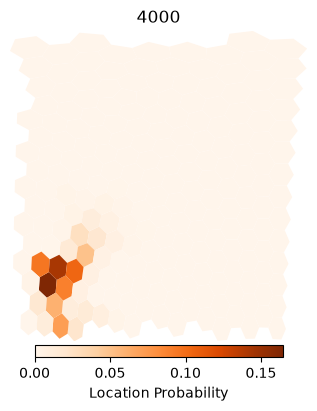

...

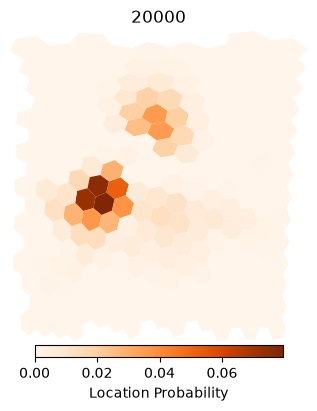

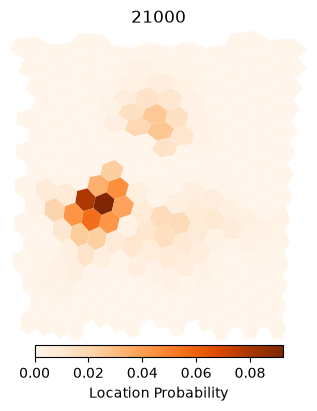

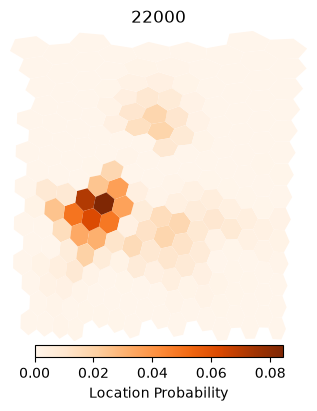

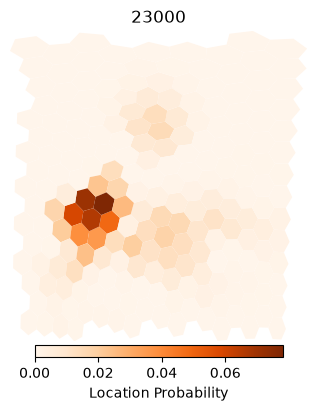

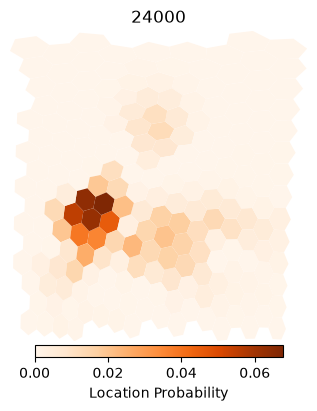

In [49]:
ts = tskit.load("../2_creating_input_files/dataset/trees/0.trees")
tree = ts.simplify().first()

times = range(0,25000,1000)

locations = tct.track_lineage_over_time(
    sample=40,
    times=times,
    tree=tree,
    world_map=world_map,
    parameters=[0.00036968]
)

for t,time in enumerate(times):
    hex_euro[f"locations_{time}"] = locations[t]
    
    base = hex_euro.plot(
        column=locations[t],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )
    
    plt.title(time)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

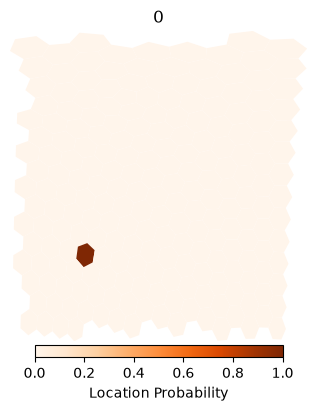

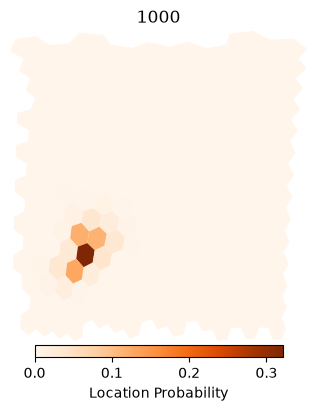

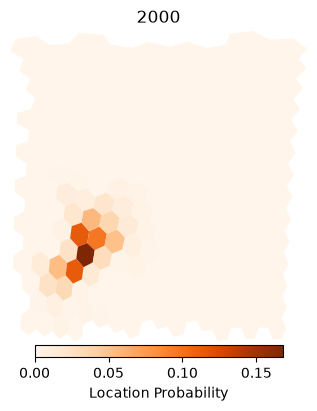

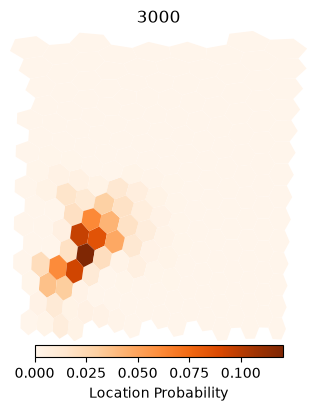

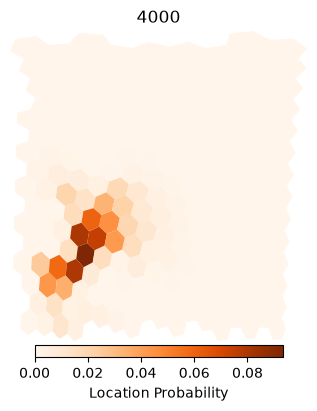

...

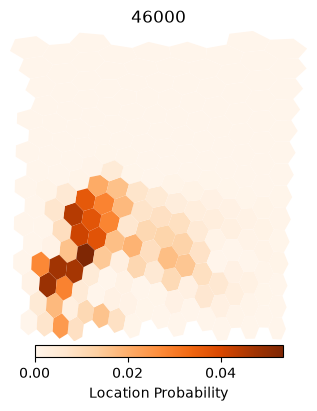

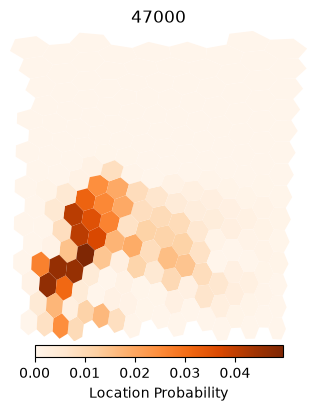

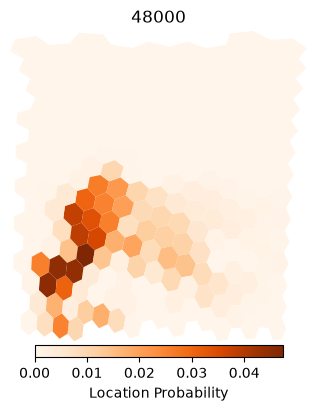

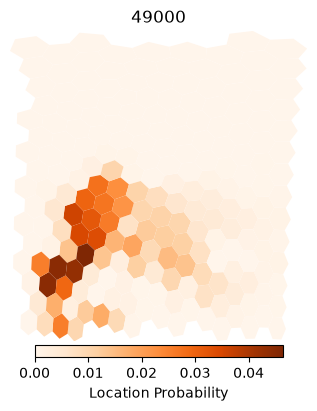

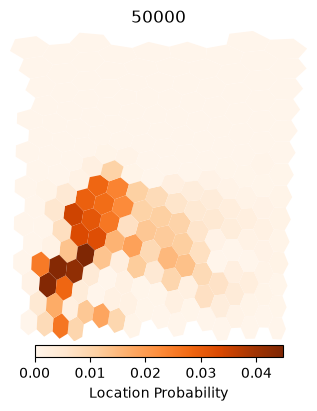

In [17]:
ts = tskit.load("../2_creating_input_files/dataset/trees/2.trees")
tree = ts.simplify().first()

times = range(0,51000,1000)

locations = tct.track_lineage_over_time(
    sample=0,
    times=times,
    tree=tree,
    world_map=world_map,
    parameters=[0.00036968]
)

for t,time in enumerate(times):
    hex_euro[f"locations_{time}"] = locations[t]
    
    base = hex_euro.plot(
        column=locations[t],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )
    
    plt.title(time)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

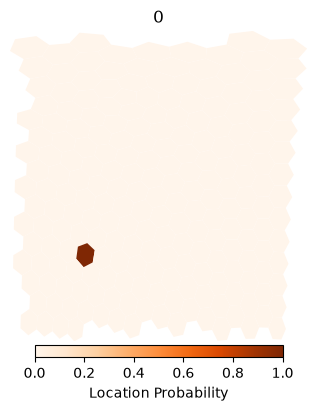

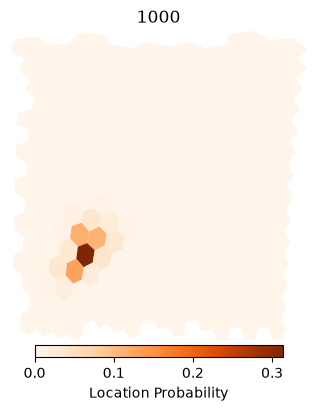

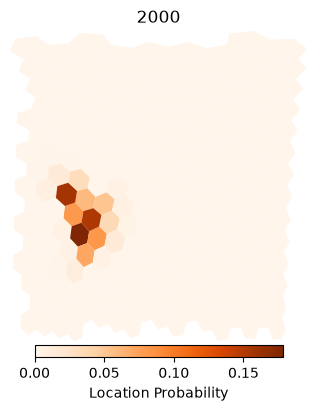

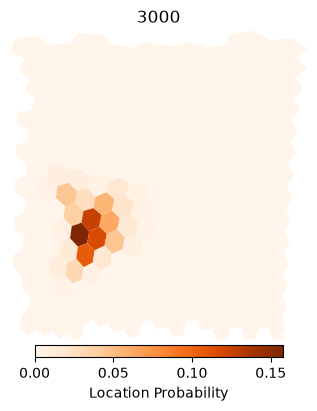

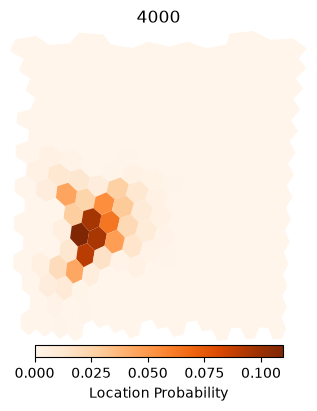

...

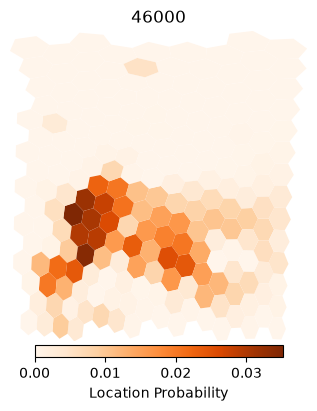

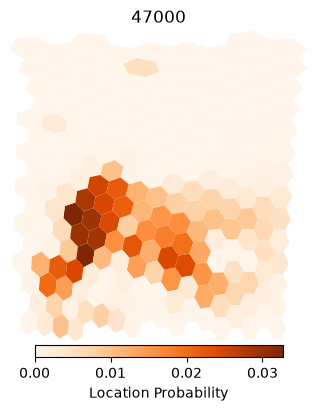

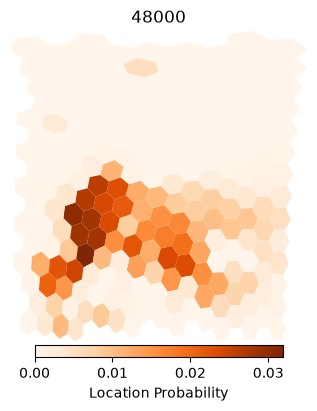

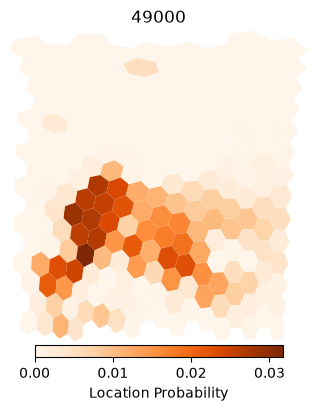

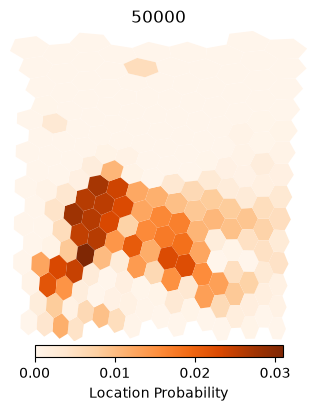

In [18]:
ts = tskit.load("../2_creating_input_files/dataset/trees/3.trees")
tree = ts.simplify().first()

times = range(0,51000,1000)

locations = tct.track_lineage_over_time(
    sample=0,
    times=times,
    tree=tree,
    world_map=world_map,
    parameters=[0.00036968]
)

for t,time in enumerate(times):
    hex_euro[f"locations_{time}"] = locations[t]
    
    base = hex_euro.plot(
        column=locations[t],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )
    
    plt.title(time)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()

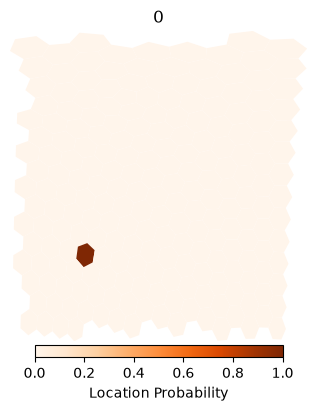

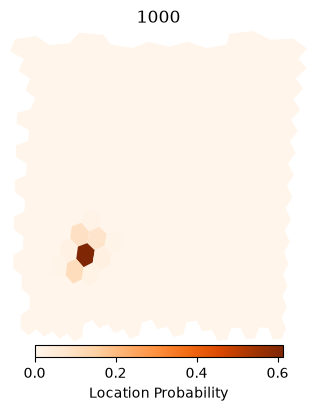

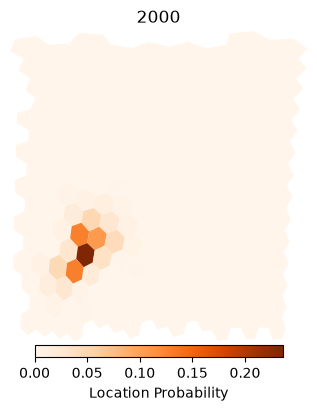

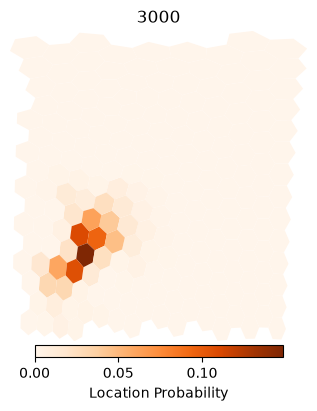

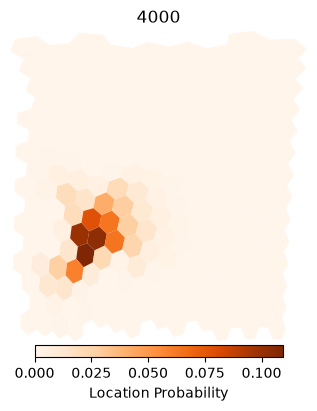

...

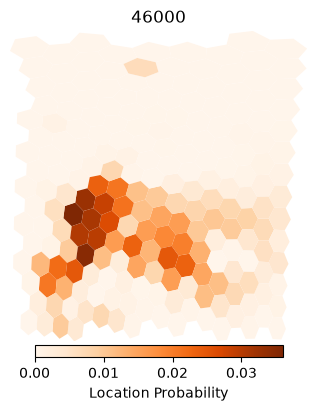

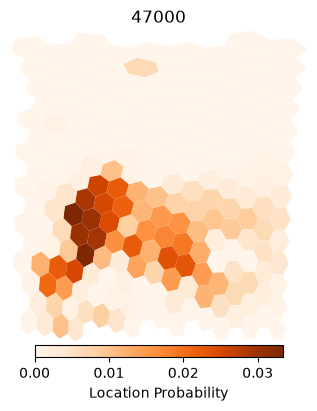

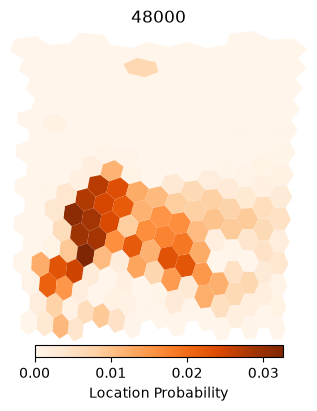

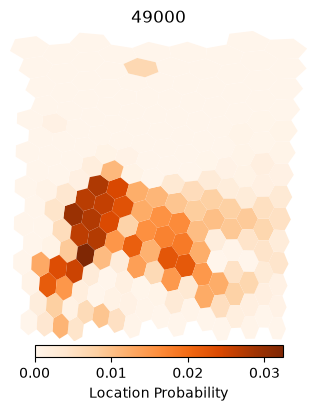

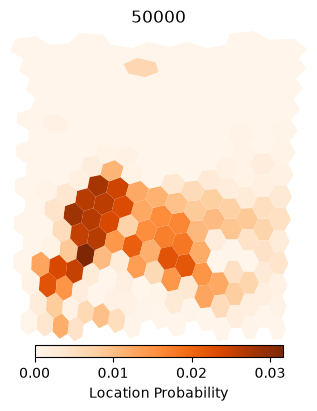

In [19]:
ts = tskit.load("../2_creating_input_files/dataset/trees/4.trees")
tree = ts.simplify().first()

times = range(0,51000,1000)

locations = tct.track_lineage_over_time(
    sample=0,
    times=times,
    tree=tree,
    world_map=world_map,
    parameters=[0.00036968]
)

for t,time in enumerate(times):
    hex_euro[f"locations_{time}"] = locations[t]
    
    base = hex_euro.plot(
        column=locations[t],
        legend=True,
        legend_kwds={"label": "Location Probability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
        cmap="Oranges"
    )
    
    plt.title(time)
    plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
    plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
    plt.axis("off")
    plt.show()